# Water Segmentation — Enhanced (indices, imbalance handling, stronger aug)

**This notebook is an enhanced version of your pipeline.** It keeps the from-scratch UNet and adds:

- Class imbalance checking and automatic weighting / focal loss option
- NDWI & MNDWI added as explicit channels (computed per-sample)
- Stronger augmentations for robustness
- Post-processing helper to remove small spurious regions

Drop this notebook into your `notebooks/` folder and run top-to-bottom. Adjust `CONFIG` if needed.

## 1) Environment & imports
Uncomment pip install line in Colab if needed.

In [ ]:
# !pip install -q tifffile albumentations==1.3.0 scikit-learn matplotlib seaborn torchvision torch --upgrade

import os, random, time, math, shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
import json

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import tifffile as tiff
from skimage import morphology, measure

print('Imports ready. device:', 'cuda' if torch.cuda.is_available() else 'cpu')

c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports ready. device: cuda


## 2) CONFIG — paths and training settings
Edit paths if needed. This matches your layout with `data/data/images` and `data/data/labels`. 

In [2]:
# Configure paths (run from notebooks/)
cwd = Path.cwd().resolve()
if cwd.name == 'notebooks':
    ROOT = cwd.parent
else:
    ROOT = cwd.parents[1] if len(cwd.parents) >= 2 else cwd

DATA_DIR = ROOT / "data" / "data"   
IMG_DIR = DATA_DIR / "images"
LAB_DIR = DATA_DIR / "labels"

_cpu = os.cpu_count() or 1
safe_workers = 0 if os.name == 'nt' else min(4, max(0, _cpu-1))

CONFIG = {
    'project_root': str(ROOT),
    'img_dir': str(IMG_DIR),
    'label_dir': str(LAB_DIR),
    'in_channels': 12,   # original 12-band count
    'height': 128, 'width': 128,
    'batch_size': 16,
    'num_workers': safe_workers,
    'epochs': 60,
    'lr': 1e-3,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'seed': 42,
    'save_dir': str(ROOT / 'experiments_enhanced'),
    # enhanced options:
    'use_indices': True,      # append NDWI + MNDWI to channel set (computed on the fly)
    'loss_type': 'bce_dice',  # options: 'bce_dice', 'weighted_bce_dice', 'focal_dice'
    'focal_gamma': 2.0,       # if focal selected
    'min_component_size': 100 # pixels, for post-processing cleanup
}

Path(CONFIG['save_dir']).mkdir(parents=True, exist_ok=True)

random.seed(CONFIG['seed']); np.random.seed(CONFIG['seed']); torch.manual_seed(CONFIG['seed'])
if CONFIG['device'].startswith('cuda'): torch.cuda.manual_seed_all(CONFIG['seed'])

print('CONFIG summary:')
print(' IMG_DIR:', CONFIG['img_dir'], 'exists?', Path(CONFIG['img_dir']).exists())
print(' LAB_DIR:', CONFIG['label_dir'], 'exists?', Path(CONFIG['label_dir']).exists())
print(' device:', CONFIG['device'], 'num_workers:', CONFIG['num_workers'])
CONFIG

CONFIG summary:
 IMG_DIR: C:\Users\Eng.Razan\Documents\Cellula Projects\Cellula-intern\data\data\images exists? True
 LAB_DIR: C:\Users\Eng.Razan\Documents\Cellula Projects\Cellula-intern\data\data\labels exists? True
 device: cuda num_workers: 0


{'project_root': 'C:\\Users\\Eng.Razan\\Documents\\Cellula Projects\\Cellula-intern',
 'img_dir': 'C:\\Users\\Eng.Razan\\Documents\\Cellula Projects\\Cellula-intern\\data\\data\\images',
 'label_dir': 'C:\\Users\\Eng.Razan\\Documents\\Cellula Projects\\Cellula-intern\\data\\data\\labels',
 'in_channels': 12,
 'height': 128,
 'width': 128,
 'batch_size': 16,
 'num_workers': 0,
 'epochs': 60,
 'lr': 0.001,
 'device': 'cuda',
 'seed': 42,
 'save_dir': 'C:\\Users\\Eng.Razan\\Documents\\Cellula Projects\\Cellula-intern\\experiments_enhanced',
 'use_indices': True,
 'loss_type': 'bce_dice',
 'focal_gamma': 2.0,
 'min_component_size': 100}

## 3) Utilities — readers, indices, normalizer

In [ ]:
## 3) Utilities — readers, indices, normalizer
import re
from pathlib import Path
import numpy as np
from PIL import Image
# tif reader already imported earlier in notebook (tifffile as tiff or rasterio)
# safe_div helper
def read_raster(path):
    p = Path(path)
    ext = p.suffix.lower()
    if ext in ('.tif', '.tiff'):
        arr = tiff.imread(str(p))
        if arr.ndim == 3:
            # if shape (H,W,C) -> transpose to (C,H,W)
            if arr.shape[2] <= 16 and arr.shape[0] > 16:
                arr = np.transpose(arr, (2,0,1))
        elif arr.ndim == 2:
            arr = arr[None,...]
        return arr.astype(np.float32)
    else:
        im = Image.open(str(p))
        if im.mode in ('1','L','P'):
            arr = np.array(im.convert('L'))[None,...]
        else:
            rgb = np.array(im.convert('RGB')).astype(np.float32)
            arr = np.transpose(rgb, (2,0,1))
        return arr.astype(np.float32)

def safe_div(a,b): return a/(b+1e-8)

CHANNEL_NAMES = ["Coastal","Blue","Green","Red","NIR","SWIR1","SWIR2","QA","MeritDEM","CopernicusDEM","ESA_WC","WaterProb"]
B_COASTAL, B_BLUE, B_GREEN, B_RED, B_NIR, B_SWIR1, B_SWIR2, B_QA, B_MERITDEM, B_COPERNICUSDEM, B_ESAWC, B_WATERPROB = range(12)

def compute_indices(arr):
    green = arr[B_GREEN]; nir = arr[B_NIR]; swir1 = arr[B_SWIR1]; red = arr[B_RED]
    ndwi = safe_div(green - nir, green + nir)
    mndwi = safe_div(green - swir1, green + swir1)
    ndvi = safe_div(nir - red, nir + red)
    return {'NDWI': ndwi, 'MNDWI': mndwi, 'NDVI': ndvi}

class BandNormalizers:
    def __init__(self, mode='clip01'):
        assert mode in ('zscore','minmax','clip01')
        self.mode = mode
        self.means = None; self.stds = None; self.mins = None; self.maxs = None

    def fit(self, file_list, sample_n=300):
        rng = np.random.default_rng(CONFIG['seed'])
        picks = rng.choice(file_list, size=min(len(file_list), sample_n), replace=False)
        sums=None; sqs=None; mins=None; maxs=None; total=0
        for p in picks:
            arr = read_raster(p)
            C = arr.shape[0]; H,W = arr.shape[1], arr.shape[2]
            if sums is None:
                sums = np.zeros(C, dtype=np.float64)
                sqs = np.zeros(C, dtype=np.float64)
                mins = np.full(C, np.inf, dtype=np.float64)
                maxs = np.full(C, -np.inf, dtype=np.float64)
            for c in range(C):
                band = arr[c].ravel()
                sums[c] += band.sum()
                sqs[c] += (band**2).sum()
                mins[c] = min(mins[c], float(band.min()))
                maxs[c] = max(maxs[c], float(band.max()))
            total += H*W
        self.means = sums/total
        self.stds  = np.sqrt(np.maximum(1e-8, sqs/total - self.means**2))
        self.mins = mins; self.maxs = maxs
        print('Normalizers computed:', self.mode)

    def transform(self, arr):
        out = arr.copy().astype(np.float32)
        C = out.shape[0]
        if self.mode == 'zscore':
            for c in range(C):
                out[c] = (out[c] - self.means[c])/(self.stds[c]+1e-8)
        elif self.mode == 'minmax':
            for c in range(C):
                mn,mx = self.mins[c], self.maxs[c]
                out[c] = (out[c] - mn)/(mx-mn+1e-8)
        else:
            for c in range(C):
                p1 = np.percentile(out[c],1); p99=np.percentile(out[c],99)
                out[c] = np.clip(out[c],p1,p99); out[c] = (out[c]-p1)/(p99-p1+1e-8)
        return out

print('Utilities ready')


Utilities ready


## 4) Data listing & matching

In [4]:
from collections import defaultdict

root_img_dir = Path(CONFIG['img_dir']); root_label_dir = Path(CONFIG['label_dir'])

img_files = sorted(list(root_img_dir.glob('*.tif')) + list(root_img_dir.glob('*.tiff')))
label_files = sorted(list(root_label_dir.glob('*.png')) + list(root_label_dir.glob('*.jpg')) + list(root_label_dir.glob('*.jpeg')) + list(root_label_dir.glob('*.tif')))

print('Found images:', len(img_files), 'Found labels:', len(label_files))
print('Example images:', [p.name for p in img_files[:10]])
print('Example labels:', [p.name for p in label_files[:10]])

label_map = {p.stem: p for p in label_files}
label_basenames = list(label_map.keys())

def match_label(img_stem):
    if img_stem in label_map: return label_map[img_stem]
    for m in label_basenames:
        if m.startswith(img_stem + '_') or m.endswith('_' + img_stem):
            return label_map[m]
    pat = re.compile(r'(^|[^0-9])' + re.escape(img_stem) + r'([^0-9]|$)')
    for m in label_basenames:
        if pat.search(m): return label_map[m]
    for m in label_basenames:
        tokens = re.findall(r'\d+', m)
        if img_stem in tokens: return label_map[m]
    for m in label_basenames:
        if img_stem in m: return label_map[m]
    return None

matches = {}
unmatched = []
used_labels = set()
for p in img_files:
    m = match_label(p.stem)
    if m:
        matches[str(p)] = str(m)
        used_labels.add(str(m))
    else:
        unmatched.append(str(p))

unused_labels = [str(p) for p in label_files if str(p) not in used_labels]
print(f"Matched: {len(matches)}  Unmatched images: {len(unmatched)}  Unused labels: {len(unused_labels)}")

Found images: 306 Found labels: 456
Example images: ['0.tif', '1.tif', '10.tif', '100.tif', '101.tif', '102.tif', '103.tif', '104.tif', '105.tif', '106.tif']
Example labels: ['0.png', '1.png', '10.png', '100.png', '100_184.png', '101.png', '101_89.png', '102.png', '102_179.png', '103.png']
Matched: 306  Unmatched images: 0  Unused labels: 150


## 5-a) EDA & class-balance check
Check water % per image and overall class balance.

Images with zero water: 45 out of 306
Mean water fraction: 0.2597528594771242 median: 0.164459228515625


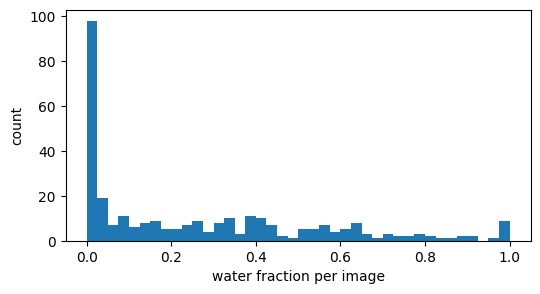

Train/Val/Test counts: 214 45 47
Train mean water fraction: 0.2235637914354556


In [11]:
frac_list = []
for img_p, lab_p in list(matches.items()):
    lab = read_raster(lab_p)[0]
    lab = (lab > 0).astype(np.uint8)
    frac_list.append(lab.mean())
frac_arr = np.array(frac_list)
print('Images with zero water:', (frac_arr==0).sum(), 'out of', len(frac_arr))
print('Mean water fraction:', frac_arr.mean(), 'median:', np.median(frac_arr))
plt.figure(figsize=(6,3)); plt.hist(frac_arr, bins=40); plt.xlabel('water fraction per image'); plt.ylabel('count'); plt.show()

# quick split stats
all_items = list(matches.items()); random.shuffle(all_items)
n = len(all_items)
n_train = int(0.7 * n); n_val = int(0.15 * n); n_test = n - n_train - n_val
train_items = all_items[:n_train]; val_items = all_items[n_train:n_train+n_val]; test_items = all_items[n_train+n_val:]
print('Train/Val/Test counts:', len(train_items), len(val_items), len(test_items))
print('Train mean water fraction:', np.mean([ (read_raster(x[1])[0]>0).mean() for x in train_items ]))

## 5-b) Per-sample visualization — per-sample bands, composites, indices

Image: 0.tif  Bands: 12  Shape: 128x128


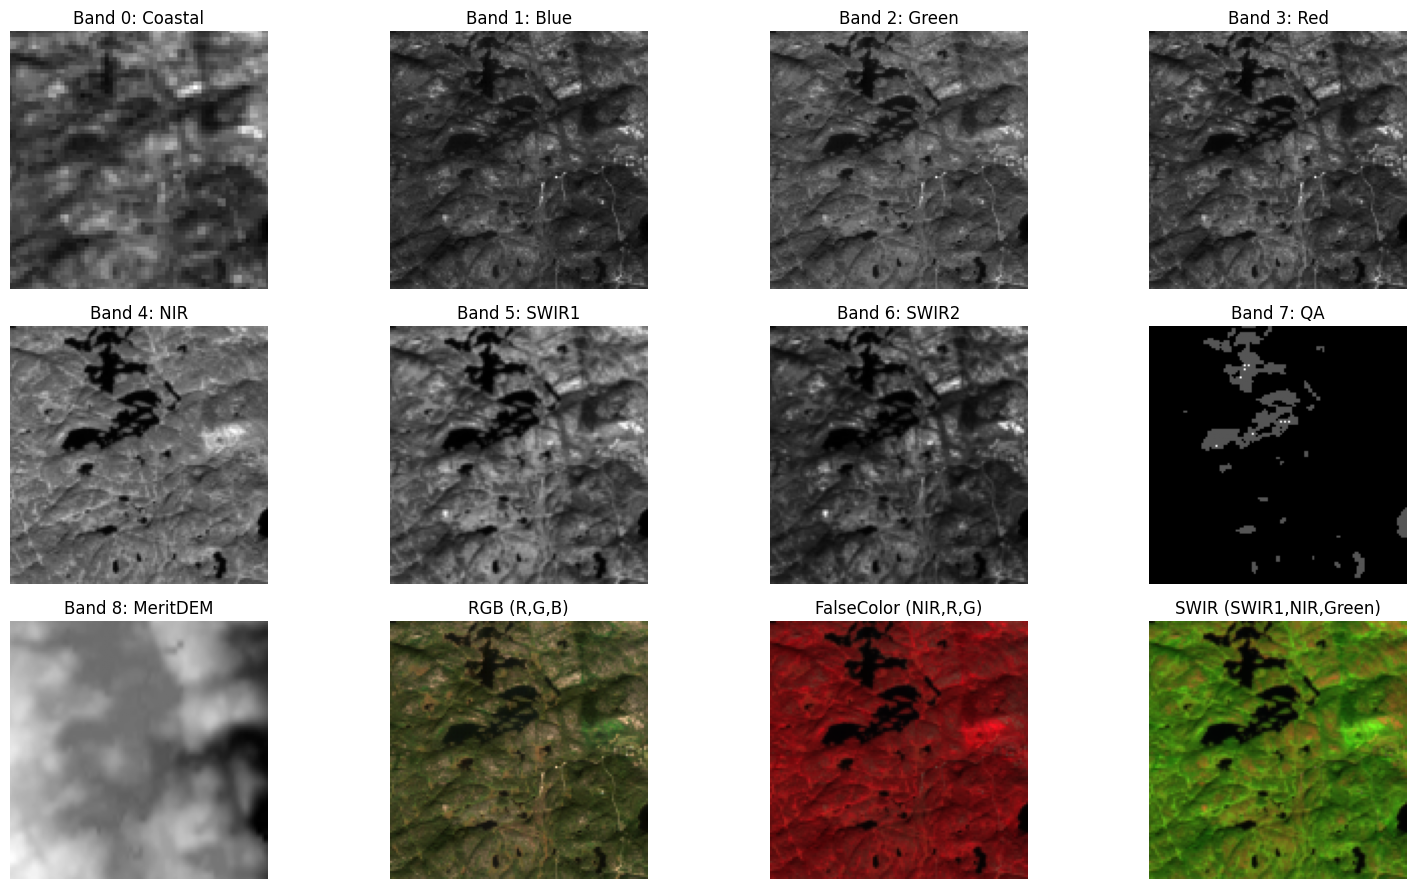

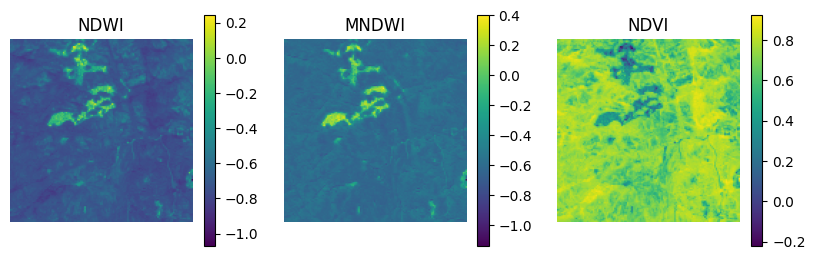

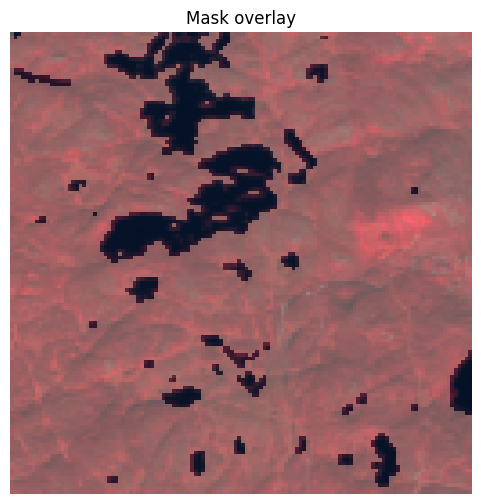

Image: 1.tif  Bands: 12  Shape: 128x128


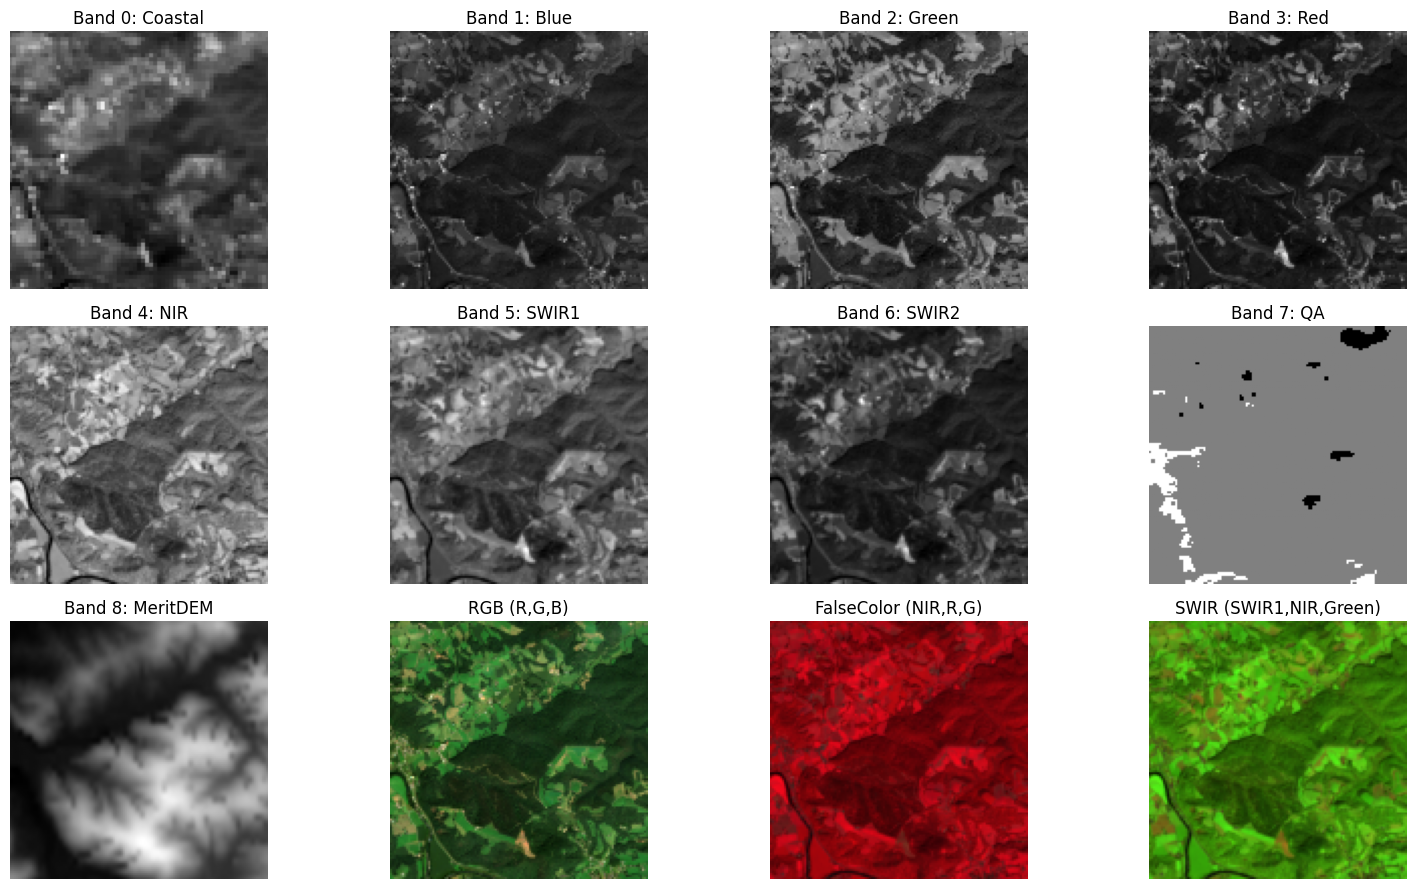

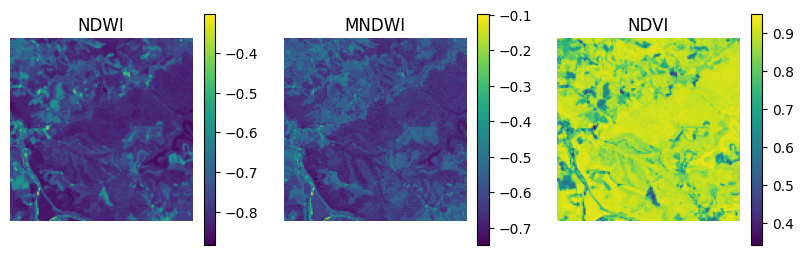

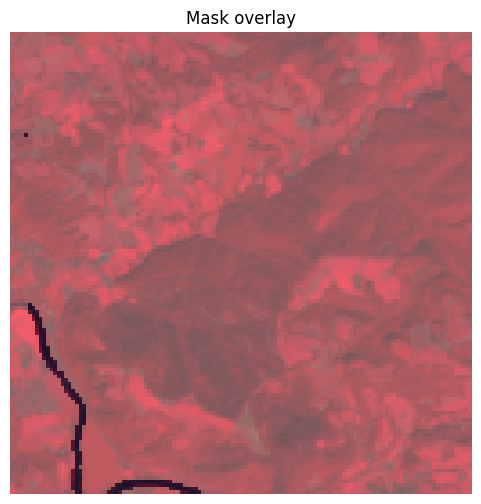

Image: 10.tif  Bands: 12  Shape: 128x128


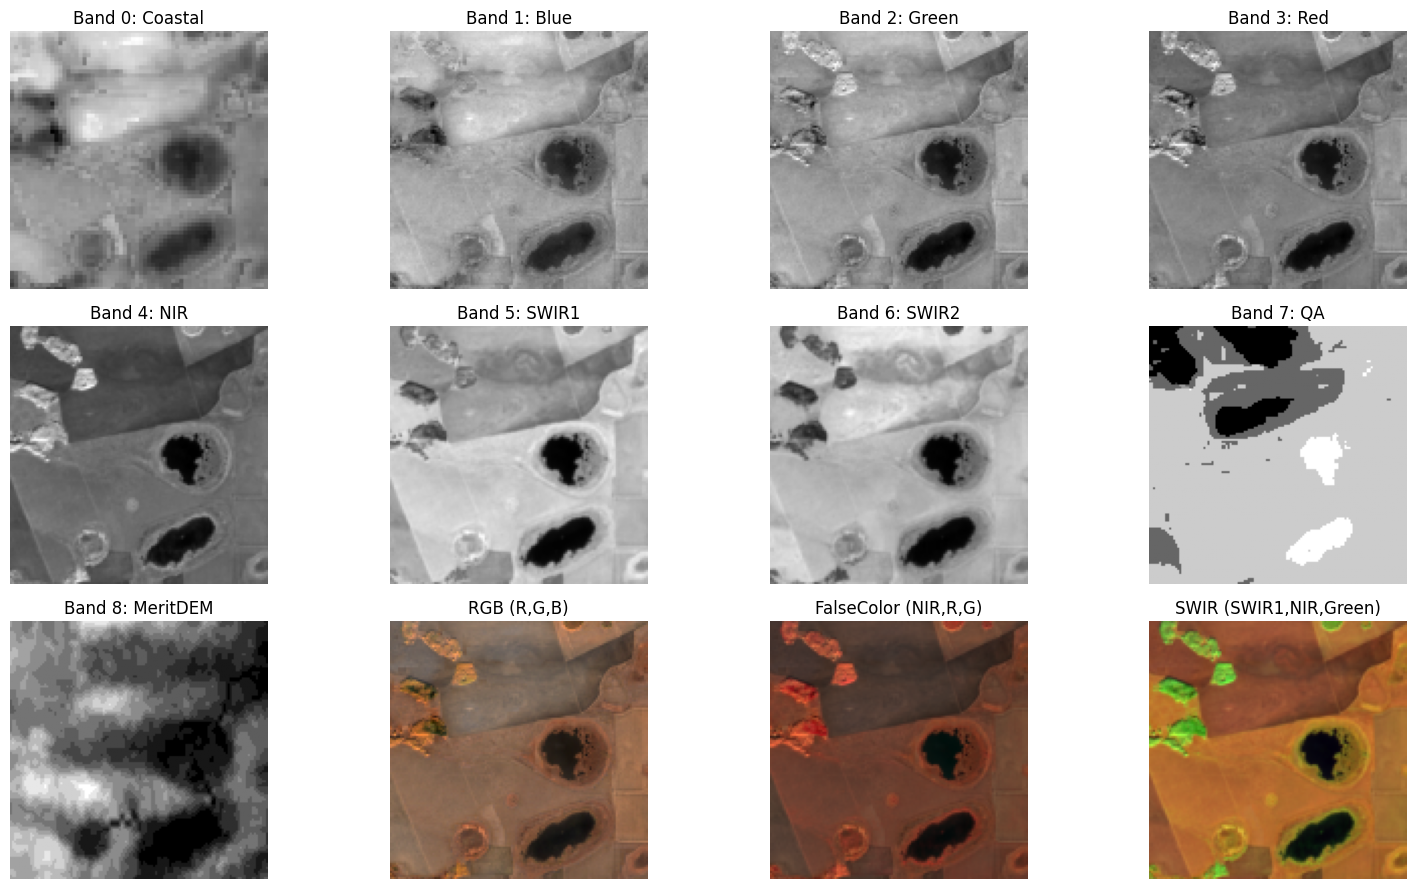

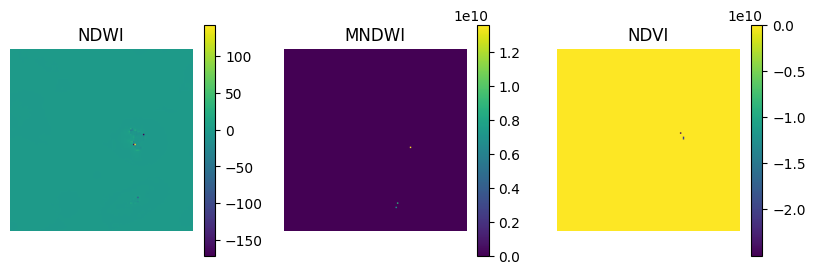

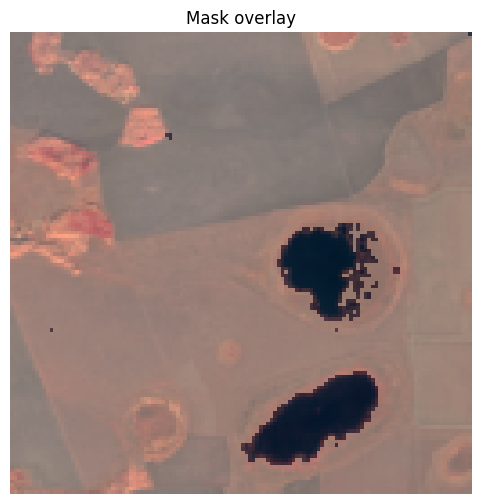

In [8]:
def show_sample_visuals(img_path, lab_path, normalizer=None, channels_to_show=None):
    arr = read_raster(img_path)  # (C,H,W)
    lab = read_raster(lab_path)[0]
    C,H,W = arr.shape
    print(f'Image: {Path(img_path).name}  Bands: {C}  Shape: {H}x{W}')
    if channels_to_show is None:
        channels_to_show = list(range(min(9,C)))
    n = len(channels_to_show)
    cols = 4
    rows = math.ceil((n+3)/cols)
    plt.figure(figsize=(4*cols, 3*rows))
    for i,ci in enumerate(channels_to_show):
        plt.subplot(rows, cols, i+1)
        b = arr[ci]
        if normalizer is not None and normalizer.means is not None and ci < len(normalizer.means):
            b_disp = normalizer.transform(arr)[ci]
        else:
            b_disp = b
        plt.imshow(b_disp, cmap='gray'); plt.title(f'Band {ci}: {CHANNEL_NAMES[ci]}'); plt.axis('off')
    def mk_comp(a,b,c):
        comp = np.stack([arr[a], arr[b], arr[c]], axis=-1)
        comp = (comp - comp.min())/(comp.max()-comp.min()+1e-8)
        return comp
    comps = [('RGB (R,G,B)', mk_comp(B_RED,B_GREEN,B_BLUE)),
             ('FalseColor (NIR,R,G)', mk_comp(B_NIR,B_RED,B_GREEN)),
             ('SWIR (SWIR1,NIR,Green)', mk_comp(B_SWIR1,B_NIR,B_GREEN))]
    for j,(name,comp) in enumerate(comps):
        plt.subplot(rows, cols, n+1+j); plt.imshow(comp); plt.title(name); plt.axis('off')
    plt.tight_layout(); plt.show()
    inds = compute_indices(arr)
    plt.figure(figsize=(10,3))
    plt.subplot(1,3,1); plt.imshow(inds['NDWI']); plt.title('NDWI'); plt.colorbar(); plt.axis('off')
    plt.subplot(1,3,2); plt.imshow(inds['MNDWI']); plt.title('MNDWI'); plt.colorbar(); plt.axis('off')
    plt.subplot(1,3,3); plt.imshow(inds['NDVI']); plt.title('NDVI'); plt.colorbar(); plt.axis('off')
    plt.show()
    fc = mk_comp(B_NIR,B_RED,B_GREEN)
    plt.figure(figsize=(6,6)); plt.imshow(fc); plt.imshow(lab, alpha=0.35, cmap='Blues'); plt.title('Mask overlay'); plt.axis('off'); plt.show()

# show first 3 examples
for img_p, lab_p in list(matches.items())[:3]:
    show_sample_visuals(img_p, lab_p)

## 6) Channel selection & Normalization
We'll append NDWI & MNDWI if enabled.

Base channels: [0, 1, 2, 3, 4, 5, 6, 8, 11] ['Coastal', 'Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2', 'MeritDEM', 'WaterProb']
Using 200 samples for channel statistics


C:\Users\Eng.Razan\AppData\Local\Temp\ipykernel_22368\3113959859.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([means[:,i] for i in range(C)], labels=labels, showfliers=False)
C:\Users\Eng.Razan\AppData\Local\Temp\ipykernel_22368\3113959859.py:84: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([stds[:,i] for i in range(C)], labels=labels, showfliers=False)


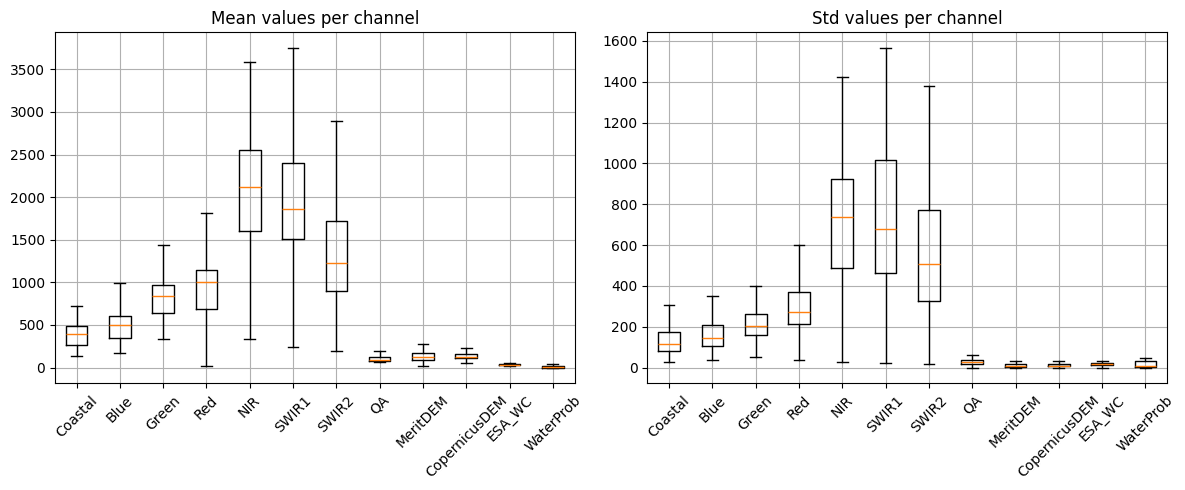

Normalizers computed: clip01
Saved normalizer stats to C:\Users\Eng.Razan\Documents\Cellula Projects\Cellula-intern\experiments_enhanced\normalizer_stats.npz


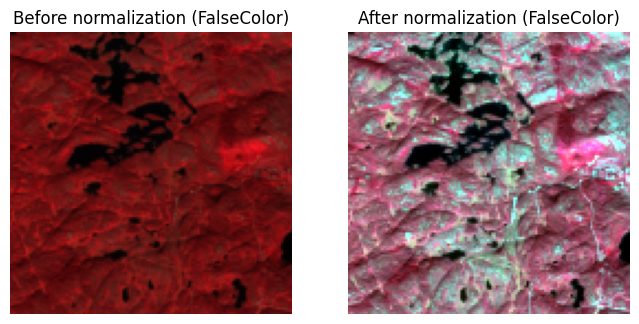

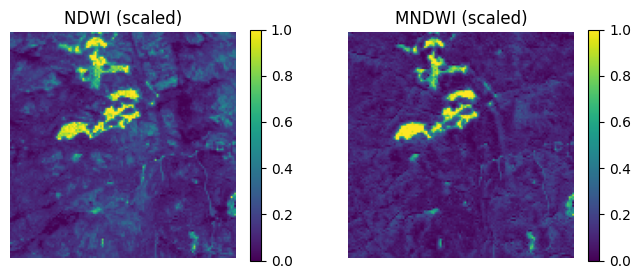

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import os

# Base channels (use the same order as your 12-band files)
base_channels = [0,1,2,3,4,5,6,8,11]
print('Base channels:', base_channels, [CHANNEL_NAMES[c] for c in base_channels])

# --- picks for channel statistics (ensure img_files exists from your file-gathering cell) ---
sample_files = [str(p) for p in img_files]   # img_files from the matching cell
sample_n = min(200, len(sample_files))
rng = np.random.default_rng(CONFIG['seed'])
picks = list(rng.choice(sample_files, size=sample_n, replace=False))
print(f"Using {len(picks)} samples for channel statistics")

# --- channel stats: per-image mean/std ---
means = []; stds = []
for p in picks:
    arr = read_raster(p)
    means.append(arr.reshape(arr.shape[0], -1).mean(axis=1))
    stds.append(arr.reshape(arr.shape[0], -1).std(axis=1))
means = np.array(means); stds = np.array(stds)
C = means.shape[1]

# Plot boxplots (use only available channels)
labels = CHANNEL_NAMES[:C]
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.boxplot([means[:,i] for i in range(C)], labels=labels, showfliers=False)
plt.xticks(rotation=45); plt.title('Mean values per channel'); plt.grid(True)

plt.subplot(1,2,2)
plt.boxplot([stds[:,i] for i in range(C)], labels=labels, showfliers=False)
plt.xticks(rotation=45); plt.title('Std values per channel'); plt.grid(True)
plt.tight_layout(); plt.show()

# --- Fit normalizer on image files (using img_files list) ---
train_files = [str(Path(p)) for p in img_files]
normalizer = BandNormalizers(mode='clip01')
normalizer.fit(train_files, sample_n=200)

# Save normalizer stats for reproducibility
os.makedirs(Path(CONFIG['save_dir']), exist_ok=True)
np.savez(Path(CONFIG['save_dir'])/'normalizer_stats.npz',
         means=normalizer.means, stds=normalizer.stds, mins=normalizer.mins, maxs=normalizer.maxs)
print('Saved normalizer stats to', Path(CONFIG['save_dir'])/'normalizer_stats.npz')

# --- Before / After normalization visual check for one sample ---
img_p, lab_p = list(matches.items())[0]
arr = read_raster(img_p)
def comp_rgb(a,b,c,arr):
    comp = np.stack([arr[a], arr[b], arr[c]], axis=-1)
    comp = (comp - comp.min())/(comp.max()-comp.min()+1e-8)
    return comp

plt.figure(figsize=(8,4))
plt.subplot(1,2,1); plt.imshow(comp_rgb(B_NIR,B_RED,B_GREEN,arr)); plt.title('Before normalization (FalseColor)'); plt.axis('off')
arr_norm = normalizer.transform(arr)
plt.subplot(1,2,2); plt.imshow(comp_rgb(B_NIR,B_RED,B_GREEN,arr_norm)); plt.title('After normalization (FalseColor)'); plt.axis('off')
plt.show()

# --- Show NDWI / MNDWI scaled ---
inds_before = compute_indices(arr)
def scale_idx(x):
    p1 = np.percentile(x,1); p99 = np.percentile(x,99); x = np.clip(x,p1,p99)
    return (x-p1)/(p99-p1+1e-8)

plt.figure(figsize=(8,3))
plt.subplot(1,2,1); plt.imshow(scale_idx(inds_before['NDWI'])); plt.title('NDWI (scaled)'); plt.colorbar(); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(scale_idx(inds_before['MNDWI'])); plt.title('MNDWI (scaled)'); plt.colorbar(); plt.axis('off')
plt.show()


## 7) Final train/val/test split

In [ ]:
# # ---------- Cell A: Stratified train / test split (no validation) ----------

all_items = list(matches.items())   # matches created earlier by your file-matching cell
n = len(all_items)
print("Total samples:", n)

# compute simple 'has_water' flag per item (same approach as before)
has_water = []
for img_p, lab_p in all_items:
    lab = read_raster(lab_p)[0]
    has_water.append(int((lab > 0).mean() > 0))

# idx lists for positive (has water) and negative (no water)
idx_pos = [i for i,v in enumerate(has_water) if v==1]
idx_neg = [i for i,v in enumerate(has_water) if v==0]

random.shuffle(idx_pos)
random.shuffle(idx_neg)

# new fractions: keep more data for training since dataset is small
n_train = int(0.85 * n)    # 85% train
n_test  = n - n_train      # 15% test

# estimate how many positive samples to put in train/test to approximately preserve pos fraction
pos_frac = sum(has_water) / (len(has_water) + 1e-12)
n_train_pos = int(round(n_train * pos_frac))
# ensure bounds
n_train_pos = min(n_train_pos, len(idx_pos))
n_train_neg = n_train - n_train_pos
n_train_neg = min(n_train_neg, len(idx_neg))

# build train indices using positives first then negatives
train_idx = idx_pos[:n_train_pos] + idx_neg[:n_train_neg]

# remaining indices for test (use set difference)
remaining = list(set(range(n)) - set(train_idx))
# if there are more remaining than needed (due to rounding), randomly pick n_test of them
random.shuffle(remaining)
test_idx = remaining[:n_test]

# final shuffle
random.shuffle(train_idx); random.shuffle(test_idx)

train_matches = dict([all_items[i] for i in train_idx])
test_matches  = dict([all_items[i] for i in test_idx])

print(f"Train/Test splits -> Train: {len(train_matches)}, Test: {len(test_matches)}")
# quick class balance info
def mean_water_fraction(items):
    return np.mean([ (read_raster(x[1])[0] > 0).mean() for x in items ])
print("Overall mean water fraction:", np.mean(has_water))
print("Train mean water fraction:", mean_water_fraction([all_items[i] for i in train_idx]))
print("Test mean water fraction:", mean_water_fraction([all_items[i] for i in test_idx]))


Total samples: 306
Train/Test splits -> Train: 260, Test: 46
Overall mean water fraction: 0.8529411764705882
Train mean water fraction: 0.2446986271784856
Test mean water fraction: 0.34484199855638586


## 8) Dataset & Dataloaders (compute indices on the fly)

In [54]:
class WaterDataset(Dataset):
    def __init__(self, matches, base_channels, normalizer, transform=None, use_indices=True):
        self.items = list(matches.items())
        self.base_channels = base_channels
        self.normalizer = normalizer
        self.transform = transform
        self.use_indices = use_indices
    def __len__(self): return len(self.items)
    def __getitem__(self, idx):
        img_path, lab_path = self.items[idx]
        arr = read_raster(img_path)
        sel = arr[self.base_channels]
        if self.use_indices:
            inds = compute_indices(arr)
            ndwi = inds['NDWI'][None,...]; mndwi = inds['MNDWI'][None,...]
            sel = np.concatenate([sel, ndwi, mndwi], axis=0)
        # normalize selected channels (original bands via normalizer, indices via percentile clip)
        k = min(sel.shape[0], len(self.normalizer.means))
        sel_norm = self.normalizer.transform(sel[:k])
        if sel.shape[0] > k:
            def scale_idx(x):
                p1 = np.percentile(x,1); p99 = np.percentile(x,99)
                x = np.clip(x, p1, p99)
                return (x - p1) / (p99 - p1 + 1e-8)
            extra = np.stack([scale_idx(sel[-2]), scale_idx(sel[-1])], axis=0)
            sel_norm = np.concatenate([sel_norm, extra], axis=0)
        lab = read_raster(lab_path)[0]
        lab = (lab > 0).astype(np.float32)
        img_hwc = np.transpose(sel_norm, (1,2,0)).astype(np.float32)
        lab_hwc = lab[..., None].astype(np.float32)
        if self.transform:
            aug = self.transform(image=img_hwc, mask=lab_hwc)
            img_hwc = aug['image']; lab_hwc = aug['mask']
        if isinstance(img_hwc, np.ndarray):
            img_tensor = torch.from_numpy(np.transpose(img_hwc, (2,0,1))).float()
        else:
            img_tensor = img_hwc.float()
        if isinstance(lab_hwc, np.ndarray):
            mask_tensor = torch.from_numpy(np.transpose(lab_hwc, (2,0,1))).float()
        else:
            if lab_hwc.dim() == 3 and lab_hwc.shape[2] == 1:
                mask_tensor = lab_hwc.permute(2,0,1).float()
            elif lab_hwc.dim() == 2:
                mask_tensor = lab_hwc.unsqueeze(0).float()
            else:
                mask_tensor = lab_hwc.float()
        return img_tensor, mask_tensor

# stronger augmentations (train) and deterministic transform for test
train_tf = A.Compose([
    A.RandomCrop(CONFIG['height'], CONFIG['width']),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(p=0.5, brightness_limit=0.2, contrast_limit=0.2),
    A.RandomGamma(p=0.3),
    A.GaussNoise(p=0.2),
    A.CoarseDropout(max_holes=8, max_height=8, max_width=8, p=0.2),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.15, rotate_limit=15, p=0.5, border_mode=0),
    A.Normalize(),
    ToTensorV2()
])
test_tf = A.Compose([
    A.CenterCrop(CONFIG['height'], CONFIG['width']),
    A.Normalize(),
    ToTensorV2()
])

# base_channels should be set earlier (if not, use your default)
try:
    base_channels
except NameError:
    base_channels = [0,1,2,3,4,5,6,8,11]
print("Using base channels:", base_channels, [CHANNEL_NAMES[c] for c in base_channels])

# create datasets
train_ds = WaterDataset(train_matches, base_channels, normalizer, transform=train_tf, use_indices=CONFIG.get('use_indices', True))
test_ds  = WaterDataset(test_matches, base_channels, normalizer, transform=test_tf, use_indices=CONFIG.get('use_indices', True))

# dataloaders
train_dl = DataLoader(train_ds, batch_size=CONFIG['batch_size'], shuffle=True, num_workers=CONFIG['num_workers'], pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=CONFIG['batch_size'], shuffle=False, num_workers=CONFIG['num_workers'], pin_memory=True)

print('Dataloaders ready. Sample batch shapes:')
bimgs, bmasks = next(iter(train_dl))
print('imgs', bimgs.shape, 'masks', bmasks.shape)



Using base channels: [0, 1, 2, 3, 4, 5, 6, 8, 11] ['Coastal', 'Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2', 'MeritDEM', 'WaterProb']
Dataloaders ready. Sample batch shapes:
imgs torch.Size([16, 11, 128, 128]) masks torch.Size([16, 1, 128, 128])


C:\Users\Eng.Razan\AppData\Local\Temp\ipykernel_22368\1577575245.py:58: UserWarning: Argument(s) 'max_holes, max_height, max_width' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=8, max_width=8, p=0.2),
c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [ ]:
# ---------- Cell C: Oversampling train images that contain water ----------
from torch.utils.data import WeightedRandomSampler

# Build weight per train sample: boost images that *contain* water
train_items = train_ds.items  # list of (img_path, lab_path) used by train_ds
sample_weights = []
for img_path, lab_path in train_items:
    lab = read_raster(lab_path)[0]
    frac = (lab > 0).mean()
    # weight water-containing images higher;
    w = 1.0 if frac > 0 else 0.2
    sample_weights.append(w)

sample_weights = np.array(sample_weights, dtype=np.float32)
# optional normalize (not required by WeightedRandomSampler)
sample_weights = sample_weights / (sample_weights.sum() + 1e-12)

# Weighted sampler (replacement=True allows oversampling of minority)
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# Recreate train DataLoader to use sampler (set shuffle=False when using sampler)
train_dl = DataLoader(train_ds, batch_size=CONFIG['batch_size'], sampler=sampler,
                      num_workers=CONFIG['num_workers'], pin_memory=True)
print("Created oversampled train_dl. Example batch shapes:", next(iter(train_dl))[0].shape, next(iter(train_dl))[1].shape)



Created oversampled train_dl. Example batch shapes: torch.Size([16, 11, 128, 128]) torch.Size([16, 1, 128, 128])


## 9) Model (UNet from-scratch)

In [19]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class UNetSmall(nn.Module):
    def __init__(self, in_channels=9, out_channels=1, filters=[32,64,128,256]):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, filters[0])
        self.pool = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(filters[0], filters[1])
        self.enc3 = DoubleConv(filters[1], filters[2])
        self.enc4 = DoubleConv(filters[2], filters[3])

        self.up3 = nn.ConvTranspose2d(filters[3], filters[2], kernel_size=2, stride=2)
        self.dec3 = DoubleConv(filters[3], filters[2])
        self.up2 = nn.ConvTranspose2d(filters[2], filters[1], kernel_size=2, stride=2)
        self.dec2 = DoubleConv(filters[2], filters[1])
        self.up1 = nn.ConvTranspose2d(filters[1], filters[0], kernel_size=2, stride=2)
        self.dec1 = DoubleConv(filters[1], filters[0])

        self.out_conv = nn.Conv2d(filters[0], out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        d3 = self.up3(e4); d3 = torch.cat([d3, e3], dim=1); d3 = self.dec3(d3)
        d2 = self.up2(d3); d2 = torch.cat([d2, e2], dim=1); d2 = self.dec2(d2)
        d1 = self.up1(d2); d1 = torch.cat([d1, e1], dim=1); d1 = self.dec1(d1)
        return self.out_conv(d1)

in_ch = (len(base_channels) + (2 if CONFIG['use_indices'] else 0))
model = UNetSmall(in_channels=in_ch, out_channels=1).to(CONFIG['device'])
print('UNetSmall ready with', in_ch, 'input channels')

UNetSmall ready with 11 input channels


## 10) Loss functions: Dice + (BCE | weighted BCE | Focal)

In [20]:
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__(); self.eps=eps
    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        num = 2*(probs*targets).sum(dim=(2,3)) + self.eps
        den = probs.sum(dim=(2,3)) + targets.sum(dim=(2,3)) + self.eps
        return 1 - (num/den).mean()

def dice_score_torch(outputs, targets, threshold=0.5):
    outputs = torch.sigmoid(outputs)
    outputs = (outputs > threshold).float()
    inter = (outputs * targets).sum(dim=(1,2,3))
    union = outputs.sum(dim=(1,2,3)) + targets.sum(dim=(1,2,3))
    dice = (2*inter + 1e-6)/(union + 1e-6)
    return dice.mean().item()

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, reduction='mean'):
        super().__init__(); self.gamma=gamma; self.reduction=reduction
    def forward(self, logits, targets):
        prob = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        p_t = prob*targets + (1-prob)*(1-targets)
        loss = ce * ((1 - p_t) ** self.gamma)
        return loss.mean() if self.reduction=='mean' else loss.sum()

def make_loss_function(train_matches):
    pos_counts = 0; total = 0
    for p,_ in train_matches.items():
        lab = read_raster(_)[0]; m = (lab > 0).astype(np.uint8)
        pos_counts += m.sum(); total += m.size
    pos_frac = pos_counts / (total + 1e-8); neg_frac = 1 - pos_frac
    print('Train positive pixel fraction:', pos_frac)
    pos_weight = torch.tensor([neg_frac / (pos_frac + 1e-8)], dtype=torch.float32).to(CONFIG['device'])
    print('Suggested pos_weight for BCE:', float(pos_weight))
    dice = DiceLoss(); focal = FocalLoss(gamma=CONFIG.get('focal_gamma',2.0))
    if CONFIG['loss_type'] == 'bce_dice':
        bce = nn.BCEWithLogitsLoss()
        return lambda outputs, targets: 0.5*bce(outputs, targets) + 0.5*dice(outputs, targets)
    elif CONFIG['loss_type'] == 'weighted_bce_dice':
        bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        return lambda outputs, targets: 0.5*bce(outputs, targets) + 0.5*dice(outputs, targets)
    elif CONFIG['loss_type'] == 'focal_dice':
        return lambda outputs, targets: 0.5*focal(outputs, targets) + 0.5*dice(outputs, targets)
    else:
        bce = nn.BCEWithLogitsLoss(); return lambda outputs, targets: 0.5*bce(outputs, targets) + 0.5*dice(outputs, targets)

combined_loss = make_loss_function(train_matches)
print('Combined loss ready:', CONFIG['loss_type'])

Train positive pixel fraction: 0.24469862717848498
Suggested pos_weight for BCE: 3.0866594314575195
Combined loss ready: bce_dice


## 11) Optimizer & Scheduler

In [21]:
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG['lr'], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
print('Optimizer ready')

Optimizer ready


## 12) Training loop

In [ ]:
# ---------- Cell D: Training loop (evaluate on test each epoch) ----------
best_test_loss = float('inf')
history = {'train_loss':[], 'test_loss':[], 'test_iou':[], 'test_dice':[]}
EPOCHS = CONFIG['epochs']; device = CONFIG['device']

for epoch in range(EPOCHS):
    t0 = time.time()
    # --- training ---
    model.train()
    running_loss = 0.0; running_dice = 0.0; n_batches = 0
    for imgs, masks in train_dl:
        imgs = imgs.to(device); masks = masks.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = combined_loss(outputs, masks)
        loss.backward(); optimizer.step()

        running_loss += loss.item()
        running_dice += dice_score_torch(outputs, masks)
        n_batches += 1

    avg_train_loss = running_loss / n_batches if n_batches else 0.0

    # --- test evaluation (in place of previous validation) ---
    model.eval()
    test_loss = 0.0; test_iou = 0.0; test_dice = 0.0; tb = 0
    with torch.no_grad():
        for imgs, masks in test_dl:
            imgs = imgs.to(device); masks = masks.to(device)
            outputs = model(imgs)
            test_loss += combined_loss(outputs, masks).item()
            preds = (torch.sigmoid(outputs) > 0.5).float()
            inter = (preds * masks).sum(dim=(1,2,3))
            union = (preds + masks - preds*masks).sum(dim=(1,2,3)) + 1e-8
            test_iou += (inter/union).mean().item()
            test_dice += dice_score_torch(outputs, masks)
            tb += 1

    avg_test_loss = test_loss / tb if tb else 0.0
    avg_test_iou  = test_iou / tb if tb else 0.0
    avg_test_dice = test_dice / tb if tb else 0.0

    # scheduler step on test loss
    scheduler.step(avg_test_loss)

    # save best model based on test loss
    if avg_test_loss < best_test_loss:
        best_test_loss = avg_test_loss
        torch.save(model.state_dict(), Path(CONFIG['save_dir'])/'best_model.pth')
        print(f"Epoch {epoch+1}: New best model saved!")

    # store history
    history['train_loss'].append(avg_train_loss)
    history['test_loss'].append(avg_test_loss)
    history['test_iou'].append(avg_test_iou)
    history['test_dice'].append(avg_test_dice)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} | Test Loss: {avg_test_loss:.4f} | Test IoU: {avg_test_iou:.4f} | Test Dice: {avg_test_dice:.4f} | Time: {time.time()-t0:.1f}s")

# save history
os.makedirs(Path(CONFIG['save_dir']), exist_ok=True)
with open(Path(CONFIG['save_dir'])/'history.json', 'w') as f:
    json.dump(history, f)
print("Training finished")


Epoch 1: New best model saved!
Epoch 1/60 | Train Loss: 0.5887 | Test Loss: 0.7245 | Test IoU: 0.0000 | Test Dice: 0.1518 | Time: 13.8s
Epoch 2/60 | Train Loss: 0.4863 | Test Loss: 2.3012 | Test IoU: 0.3408 | Test Dice: 0.4211 | Time: 15.1s
Epoch 3/60 | Train Loss: 0.4675 | Test Loss: 2.2712 | Test IoU: 0.0000 | Test Dice: 0.1518 | Time: 13.2s
Epoch 4/60 | Train Loss: 0.4542 | Test Loss: 8.4854 | Test IoU: 0.3409 | Test Dice: 0.4211 | Time: 8.0s
Epoch 5/60 | Train Loss: 0.4383 | Test Loss: 3.6341 | Test IoU: 0.0000 | Test Dice: 0.1518 | Time: 7.5s
Epoch 6: New best model saved!
Epoch 6/60 | Train Loss: 0.4352 | Test Loss: 0.5128 | Test IoU: 0.3378 | Test Dice: 0.5769 | Time: 10.8s
Epoch 7: New best model saved!
Epoch 7/60 | Train Loss: 0.4226 | Test Loss: 0.3884 | Test IoU: 0.5173 | Test Dice: 0.7023 | Time: 7.9s
Epoch 8/60 | Train Loss: 0.4175 | Test Loss: 2.4262 | Test IoU: 0.3409 | Test Dice: 0.4211 | Time: 7.0s
Epoch 9/60 | Train Loss: 0.4136 | Test Loss: 3.8241 | Test IoU: 0.0000 

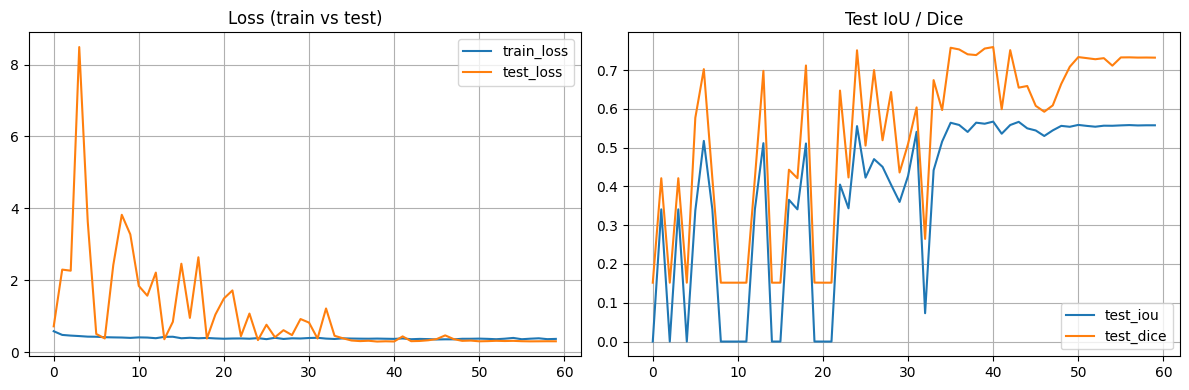

In [ ]:
## ---------- Plot train/test curves ----------
import matplotlib.pyplot as plt
h = history
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(h['train_loss'], label='train_loss')
plt.plot(h['test_loss'], label='test_loss')
plt.legend(); plt.title('Loss (train vs test)'); plt.grid(True)

plt.subplot(1,2,2)
plt.plot(h['test_iou'], label='test_iou')
plt.plot(h['test_dice'], label='test_dice')
plt.legend(); plt.title('Test IoU / Dice'); plt.grid(True)

plt.tight_layout(); plt.show()


## 13) Test evaluation & postprocessing

In [ ]:
# ----------  Final Test Evaluation & Postprocessing ----------
# load best model
model.load_state_dict(torch.load(Path(CONFIG['save_dir'])/'best_model.pth'))
model.eval(); device = CONFIG['device']

test_loss = 0.0; test_iou = 0.0; test_dice = 0.0; tb = 0
with torch.no_grad():
    for imgs, masks in test_dl:
        imgs = imgs.to(device); masks = masks.to(device)
        outputs = model(imgs)
        test_loss += combined_loss(outputs, masks).item()
        preds = (torch.sigmoid(outputs) > 0.5).float()
        inter = (preds * masks).sum(dim=(1,2,3))
        union = (preds + masks - preds*masks).sum(dim=(1,2,3)) + 1e-8
        test_iou += (inter/union).mean().item()
        test_dice += dice_score_torch(outputs, masks)
        tb += 1

print('Final Test Loss:', test_loss/tb, 'Test IoU:', test_iou/tb, 'Test Dice:', test_dice/tb)

# Post-processing helper (connected-component clean)
def postprocess_mask(mask_arr, min_size=CONFIG.get('min_component_size', 100)):
    mask_bool = mask_arr.astype(bool)
    cleaned = morphology.remove_small_objects(mask_bool, min_size=min_size)
    cleaned = morphology.remove_small_holes(cleaned, area_threshold=min_size)
    return cleaned.astype(np.uint8)


C:\Users\Eng.Razan\AppData\Local\Temp\ipykernel_22368\3999913954.py:23: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(Path(CONFIG['save_dir'

Final Test Loss: 0.30181803305943805 Test IoU: 0.5643250346183777 Test Dice: 0.7386463284492493


##  Visualization & Error Maps
Show input, GT, prediction and error map with per-sample IoU/Dice.

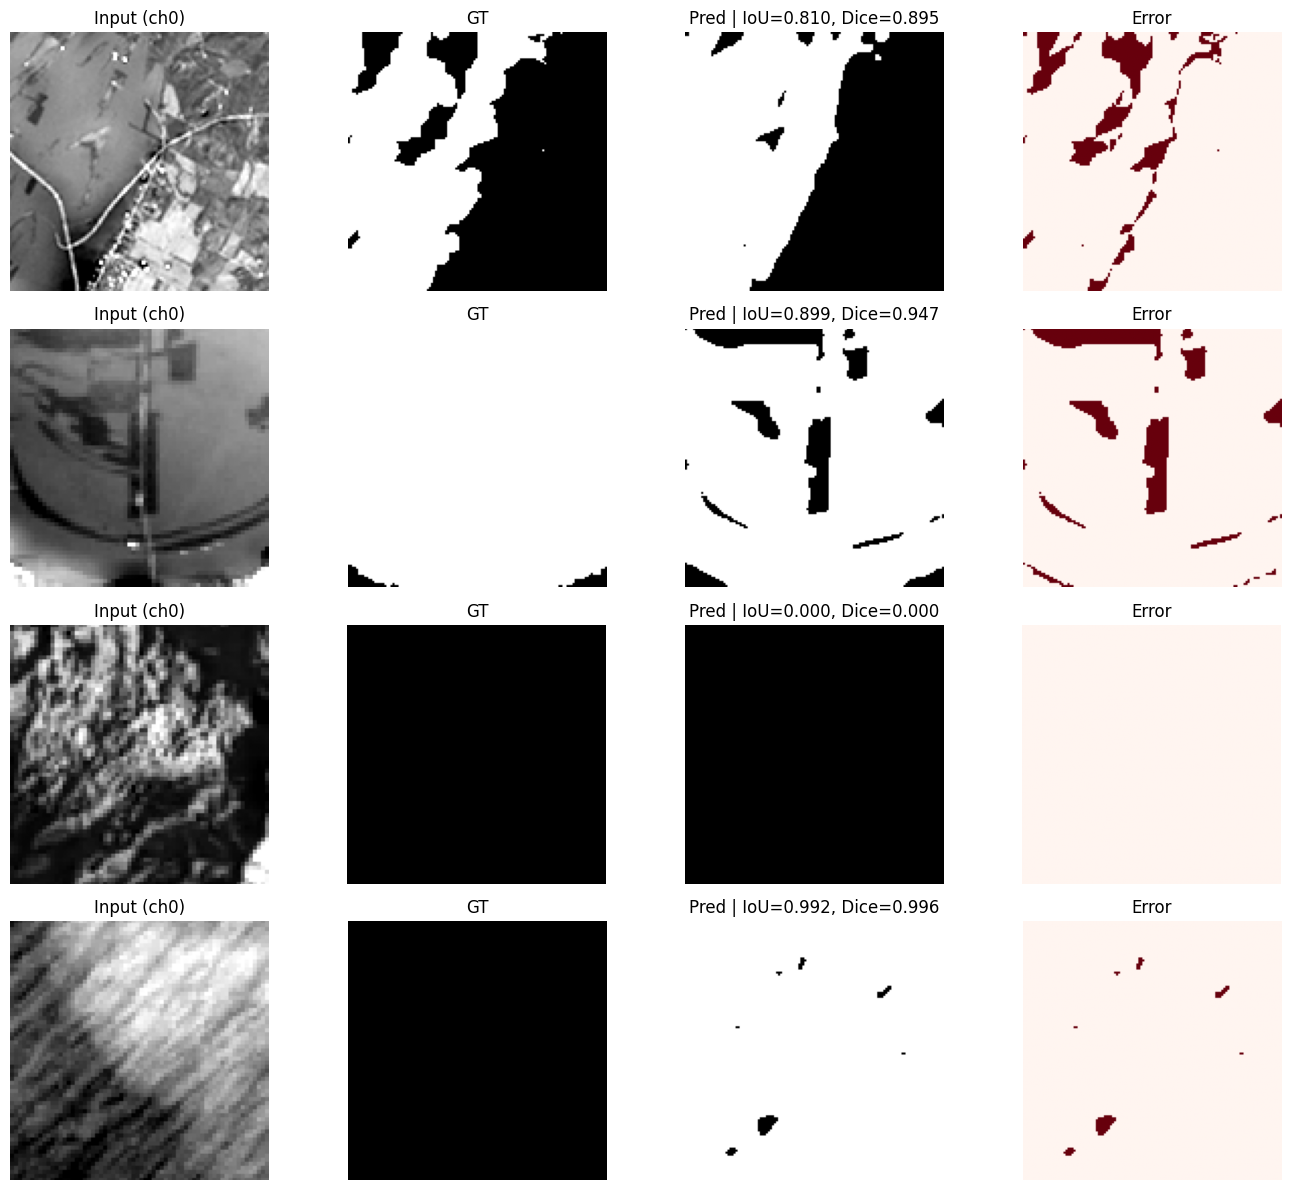

In [25]:
def visualize_with_error_maps(model, dataloader, device, num_samples=4, threshold=0.5, channel=0):
    model.eval()
    imgs, masks = next(iter(dataloader))
    imgs, masks = imgs.to(device), masks.to(device)
    with torch.no_grad():
        outputs = model(imgs)
        probs = torch.sigmoid(outputs)
        preds = (probs>threshold).float()
    n_show = min(num_samples, imgs.shape[0])
    plt.figure(figsize=(14, 3*n_show))
    for i in range(n_show):
        img = imgs[i, channel].cpu().numpy()
        gt = masks[i,0].cpu().numpy()
        pred = preds[i,0].cpu().numpy()
        inter = (gt*pred).sum(); union = ((gt+pred)>0).sum()
        iou = inter/(union+1e-8); dice = (2*inter)/(gt.sum()+pred.sum()+1e-8)
        err = (gt != pred).astype(float)
        plt.subplot(n_show,4,4*i+1); plt.imshow(img, cmap='gray'); plt.title('Input (ch{})'.format(channel)); plt.axis('off')
        plt.subplot(n_show,4,4*i+2); plt.imshow(gt, cmap='gray'); plt.title('GT'); plt.axis('off')
        plt.subplot(n_show,4,4*i+3); plt.imshow(pred, cmap='gray'); plt.title(f'Pred | IoU={iou:.3f}, Dice={dice:.3f}'); plt.axis('off')
        plt.subplot(n_show,4,4*i+4); plt.imshow(err, cmap='Reds'); plt.title('Error'); plt.axis('off')
    plt.tight_layout(); plt.show()

visualize_with_error_maps(model, test_dl, CONFIG['device'], num_samples=4, threshold=0.5)

## 14) Full evaluation & classification report

Classification report (threshold=0.5):\n
              precision    recall  f1-score   support

  Background       0.93      0.97      0.95    493769
       Water       0.94      0.86      0.90    259895

    accuracy                           0.93    753664
   macro avg       0.93      0.92      0.92    753664
weighted avg       0.93      0.93      0.93    753664



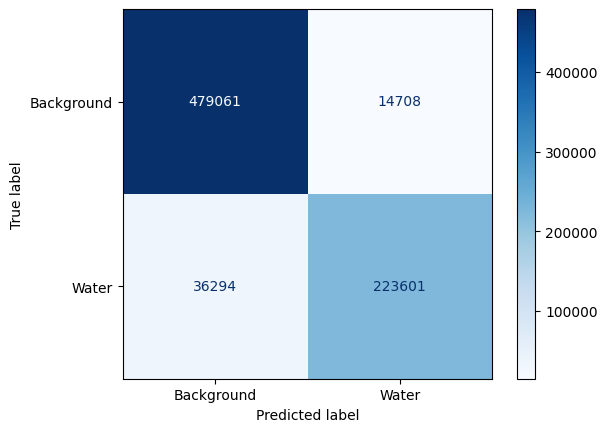

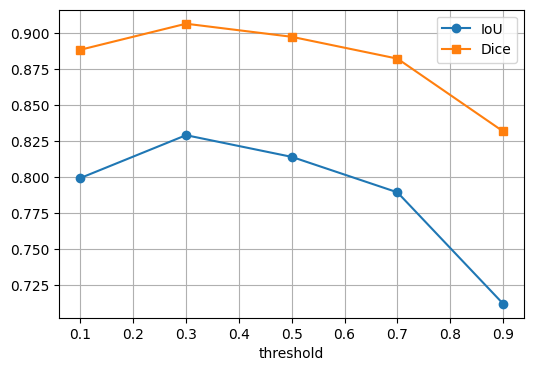

In [26]:
def full_evaluation(model, dataloader, device, thresholds=[0.1,0.3,0.5,0.7,0.9]):
    model.eval()
    y_true = []; y_probs = []
    with torch.no_grad():
        for imgs, masks in dataloader:
            imgs, masks = imgs.to(device), masks.to(device)
            outputs = model(imgs)
            probs = torch.sigmoid(outputs).cpu().numpy().ravel()
            y_probs.extend(probs); y_true.extend(masks.cpu().numpy().ravel().astype(int))
    y_true = np.array(y_true); y_probs = np.array(y_probs)
    t = 0.5
    y_pred = (y_probs > t).astype(int)
    print('Classification report (threshold=0.5):\\n'); print(classification_report(y_true, y_pred, target_names=['Background','Water']))
    cm = confusion_matrix(y_true, y_pred); disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Background','Water']); disp.plot(cmap='Blues'); plt.show()
    ious=[]; dices=[]
    for th in thresholds:
        yp = (y_probs>th).astype(int); inter = np.logical_and(y_true==1, yp==1).sum(); union = np.logical_or(y_true==1, yp==1).sum()
        iou = inter/(union+1e-8); dice = (2*inter)/(y_true.sum()+yp.sum()+1e-8); ious.append(iou); dices.append(dice)
    plt.figure(figsize=(6,4)); plt.plot(thresholds, ious, marker='o', label='IoU'); plt.plot(thresholds, dices, marker='s', label='Dice'); plt.legend(); plt.grid(True); plt.xlabel('threshold'); plt.show()

full_evaluation(model, test_dl, CONFIG['device'])

## Fine-tuning pretrained segmentation models (SMP)
We will fine-tune several encoder backbones using segmentation-models-pytorch.
Workflow:
1. Create model with pretrained encoder (imagenet).
2. Freeze encoder weights (initial training).
3. Train decoder / head.
4. Unfreeze encoder and fine-tune whole model.
5. Evaluate on test set and save best weights.


In [ ]:
# ----------  imports and device ----------
import os, time, copy
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from tqdm import tqdm
import segmentation_models_pytorch as smp

# sklearn for classification report
from sklearn.metrics import classification_report, confusion_matrix

DEVICE = torch.device(CONFIG.get('device', 'cuda' if torch.cuda.is_available() else 'cpu'))
print("Device:", DEVICE)
print("SMP version:", smp.__version__)
# confirm in_channels
print("Model input channels (CONFIG['in_channels']):", CONFIG['in_channels'])


Device: cuda
SMP version: 0.5.0
Model input channels (CONFIG['in_channels']): 12


In [ ]:
# ----------  Dataloaders for pretrained SMP models (RGB only) ----------

# Select only RGB bands
B_RED   = CHANNEL_NAMES.index("Red")
B_GREEN = CHANNEL_NAMES.index("Green")
B_BLUE  = CHANNEL_NAMES.index("Blue")

base_channels_rgb = [B_RED, B_GREEN, B_BLUE]
print("Using RGB channels:", base_channels_rgb, [CHANNEL_NAMES[c] for c in base_channels_rgb])

# Update config for SMP
CONFIG['in_channels_smp'] = len(base_channels_rgb)

# Build datasets (disable indices to keep input=3 channels only)
train_ds_smp = WaterDataset(
    train_matches,
    base_channels_rgb,
    normalizer,
    transform=train_tf,
    use_indices=False   
)
test_ds_smp = WaterDataset(
    test_matches,
    base_channels_rgb,
    normalizer,
    transform=test_tf,
    use_indices=False   
)

# Build dataloaders
train_dl_smp = DataLoader(
    train_ds_smp, batch_size=CONFIG['batch_size'],
    shuffle=True, num_workers=CONFIG['num_workers'], pin_memory=True
)
test_dl_smp = DataLoader(
    test_ds_smp, batch_size=CONFIG['batch_size'],
    shuffle=False, num_workers=CONFIG['num_workers'], pin_memory=True
)

# Quick check
xb, yb = next(iter(train_dl_smp))
print("Sample batch for pretrained SMP -> imgs:", xb.shape, "masks:", yb.shape)



Using RGB channels: [3, 2, 1] ['Red', 'Green', 'Blue']
Sample batch for pretrained SMP -> imgs: torch.Size([16, 3, 128, 128]) masks: torch.Size([16, 1, 128, 128])


In [ ]:
# ----------  SMP Dataset (select 3 channels, percentile scale, Albumentations) ----------
import albumentations as A
from albumentations.pytorch import ToTensorV2

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

class SMPDataset(Dataset):
    """Dataset for training pretrained encoder models (3-channel inputs).
    Accepts the same matches dict/list style you already use (matches = {img_path: label_path}).
    """
    def __init__(self, matches, channels, transform=None, p_lo=1, p_hi=99):
        # matches can be a dict or list of tuples
        if isinstance(matches, dict):
            self.items = list(matches.items())
        else:
            self.items = list(matches)  # assume list of (img, label)
        self.channels = channels
        self.transform = transform
        self.p_lo = p_lo; self.p_hi = p_hi

    def __len__(self): return len(self.items)

    def _scale_perc(self, ch):
        p1 = np.percentile(ch, self.p_lo)
        p99 = np.percentile(ch, self.p_hi)
        ch = np.clip(ch, p1, p99)
        ch = (ch - p1) / (p99 - p1 + 1e-8)
        return ch

    def __getitem__(self, idx):
        img_path, lab_path = self.items[idx]
        arr = read_raster(img_path)  # (C, H, W)
        sel = arr[self.channels]      # (3, H, W)
        # HWC for albumentations
        img = np.transpose(sel, (1,2,0)).astype(np.float32)  # H,W,3

        # per-channel percentile scaling to 0..1
        img_scaled = np.zeros_like(img, dtype=np.float32)
        for i in range(img.shape[2]):
            img_scaled[..., i] = self._scale_perc(img[..., i])

        # load mask (H,W) and convert to 0/1
        lab = read_raster(lab_path)[0]
        mask = (lab > 0).astype(np.float32)
        mask = mask[..., None]  # H,W,1

        if self.transform:
            augmented = self.transform(image=img_scaled, mask=mask)
            img_scaled = augmented['image']
            mask = augmented['mask']

        # ensure torch tensors in CHW
        if isinstance(img_scaled, np.ndarray):
            img_tensor = torch.from_numpy(img_scaled.transpose(2,0,1)).float()
        else:
            img_tensor = img_scaled.float()

        if isinstance(mask, np.ndarray):
            mask_tensor = torch.from_numpy(mask.transpose(2,0,1)).float()
        else:
            mask_tensor = mask.float()

        return img_tensor, mask_tensor

# Transforms for SMP run (expects input range 0..1, then Normalize with ImageNet mean/std)
train_tf_smp = A.Compose([
    A.RandomCrop(CONFIG['height'], CONFIG['width']),
    A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD, max_pixel_value=1.0),
    ToTensorV2()
])

val_tf_smp = A.Compose([
    A.CenterCrop(CONFIG['height'], CONFIG['width']),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD, max_pixel_value=1.0),
    ToTensorV2()
])

print("SMPDataset and transforms ready.")


SMPDataset and transforms ready.


In [ ]:
# ----------  create dataloaders for SMP ----------
smp_train_ds = SMPDataset(train_matches, channels=SELECTED_CHANNELS, transform=train_tf_smp)
smp_test_ds  = SMPDataset(test_matches,  channels=SELECTED_CHANNELS, transform=val_tf_smp)

train_dl_smp = DataLoader(smp_train_ds, batch_size=CONFIG['batch_size'], shuffle=True,
                          num_workers=CONFIG['num_workers'], pin_memory=True)
test_dl_smp  = DataLoader(smp_test_ds,  batch_size=CONFIG['batch_size'], shuffle=False,
                          num_workers=CONFIG['num_workers'], pin_memory=True)

bimgs, bmasks = next(iter(train_dl_smp))
print("SMP dataloaders ready. Example batch shapes -> imgs", bimgs.shape, "masks", bmasks.shape)
# Should print imgs torch.Size([B, 3, H, W]) masks torch.Size([B, 1, H, W])


SMP dataloaders ready. Example batch shapes -> imgs torch.Size([16, 3, 128, 128]) masks torch.Size([16, 128, 128, 1])


In [ ]:
# ---------- SMP model builder + helpers ----------
import segmentation_models_pytorch as smp

def build_smp_model(model_name='Unet', encoder='resnet34', in_channels=3, encoder_weights='imagenet'):
    mn = model_name.lower()
    enc = encoder
    if mn == 'unet':
        return smp.Unet(encoder_name=enc, encoder_weights=encoder_weights, in_channels=in_channels, classes=1, activation=None)
    elif mn in ('deeplabv3plus','deeplabv3+','deeplab'):
        return smp.DeepLabV3Plus(encoder_name=enc, encoder_weights=encoder_weights, in_channels=in_channels, classes=1, activation=None)
    else:
        raise ValueError("Unknown model_name: " + model_name)

def freeze_encoder(model):
    if hasattr(model, 'encoder'):
        for p in model.encoder.parameters():
            p.requires_grad = False

def unfreeze_encoder(model):
    if hasattr(model, 'encoder'):
        for p in model.encoder.parameters():
            p.requires_grad = True

print("SMP builder ready.")


SMP builder ready.


In [ ]:
# ----------  Loss functions for SMP ----------

import torch.nn as nn
import torch.nn.functional as F

# Dice loss that matches SMP outputs
def dice_loss_smp(logits, targets, eps=1e-7):
    # logits: [B, 1, H, W]
    # targets: [B, H, W] or [B, H, W, 1]
    if targets.ndim == 4 and targets.shape[1] != 1:
        # shape [B,H,W,1] -> [B,1,H,W]
        targets = targets.permute(0, 3, 1, 2)
    elif targets.ndim == 3:
        targets = targets.unsqueeze(1)  # [B,H,W] -> [B,1,H,W]

    probs = torch.sigmoid(logits)
    num = 2 * (probs * targets).sum(dim=(2, 3)) + eps
    den = probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3)) + eps
    loss = 1 - (num / den).mean()
    return loss

def make_loss_function(loss_type="bce_dice"):
    if loss_type == "bce":
        bce = nn.BCEWithLogitsLoss()
        return lambda outputs, targets: bce(outputs, targets)
    elif loss_type == "dice":
        return dice_loss_smp
    elif loss_type == "bce_dice":
        bce = nn.BCEWithLogitsLoss()
        return lambda outputs, targets: 0.5 * bce(
            outputs,
            targets.permute(0, 3, 1, 2) if targets.ndim == 4 else targets.unsqueeze(1)
        ) + 0.5 * dice_loss_smp(outputs, targets)

# Choose combined loss
loss_fn = make_loss_function("bce_dice")


In [ ]:
# ---------- Training function with mask fix ----------

def train_smp_simple(model, train_loader, val_loader, loss_fn, lr, epochs, freeze_epochs, save_dir, model_tag):
    save_dir.mkdir(parents=True, exist_ok=True)
    log_path = save_dir / f"{model_tag}_training.log"
    log_file = open(log_path, "w")

    
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_loss = float("inf")
    best_state = None
    last_state = None

    for epoch in range(epochs):
        model.train()
        running_loss, nb = 0, 0
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

            # 🔑 FIX: make masks [B,1,H,W]
            if masks.ndim == 4 and masks.shape[1] != 1:
                masks = masks.permute(0, 3, 1, 2)
            elif masks.ndim == 3:
                masks = masks.unsqueeze(1)

            optimizer.zero_grad()
            logits = model(imgs)
            loss = loss_fn(logits, masks)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            nb += 1

        avg_train_loss = running_loss / max(nb, 1)

        # Validation
        model.eval()
        val_loss, vb = 0, 0
        with torch.no_grad():
            for imgs, masks in val_loader:
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

                # 🔑 Same fix in validation
                if masks.ndim == 4 and masks.shape[1] != 1:
                    masks = masks.permute(0, 3, 1, 2)
                elif masks.ndim == 3:
                    masks = masks.unsqueeze(1)

                logits = model(imgs)
                loss = loss_fn(logits, masks)
                val_loss += loss.item()
                vb += 1

        avg_val_loss = val_loss / max(vb, 1)
        scheduler.step()

        # ---- Logging
        msg = f"Epoch {epoch+1}/{epochs} - Train loss: {avg_train_loss:.4f} - Val loss: {avg_val_loss:.4f}"
        print(msg)
        log_file.write(msg + "\n"); log_file.flush()

        # Save best
        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            best_state = model.state_dict()
            torch.save(best_state, save_dir / f"{model_tag}_best.pth")

        last_state = model.state_dict()
        torch.save(last_state, save_dir / f"{model_tag}_last.pth")

        # ---- Freeze encoder for first N epochs
        if epoch+1 == freeze_epochs:
            for param in model.encoder.parameters():
                param.requires_grad = True

    log_file.close()
    
    return best_state, last_state


In [ ]:
# ----------  build SMP model and run experiment ----------
# Choose experiment settings:
EXP = {'name':'smp_unet_res34', 'model_name':'Unet', 'encoder':'resnet34', 'epochs':20, 'lr':1e-4, 'freeze_epochs':1}

# Build model with in_channels=3 and imagenet weights
model_smp = build_smp_model(EXP['model_name'], EXP['encoder'], in_channels=CONFIG['in_channels_smp'], encoder_weights='imagenet')
model_smp = model_smp.to(DEVICE)

# print params
total_params = sum(p.numel() for p in model_smp.parameters())/1e6
trainable = sum(p.numel() for p in model_smp.parameters() if p.requires_grad)/1e6
print(f"Model params (M): total={total_params:.2f}  trainable={trainable:.2f}")

# Use your combined_loss or make a specific loss for SMP; using combined_loss (BCE + Dice) is OK:
loss_fn = combined_loss

# Train using test_dl_smp as validation (since you have only train/test)
best_state, last_state = train_smp_simple(model_smp,
                                         train_loader=train_dl_smp,
                                         val_loader=test_dl_smp,
                                         loss_fn=loss_fn,
                                         lr=EXP['lr'],
                                         epochs=EXP['epochs'],
                                         freeze_epochs=EXP['freeze_epochs'],
                                         save_dir=Path(CONFIG['save_dir']),
                                         model_tag=EXP['name'])
print("Training finished. Best model saved to", Path(CONFIG['save_dir'])/f"{EXP['name']}_best.pth")


Model params (M): total=24.44  trainable=24.44
Epoch 1/20 - Train loss: 0.7509 - Val loss: 0.6221
Epoch 2/20 - Train loss: 0.6670 - Val loss: 0.5485
Epoch 3/20 - Train loss: 0.6220 - Val loss: 0.5214
Epoch 4/20 - Train loss: 0.5849 - Val loss: 0.5012
Epoch 5/20 - Train loss: 0.5558 - Val loss: 0.4711
Epoch 6/20 - Train loss: 0.5550 - Val loss: 0.4706
Epoch 7/20 - Train loss: 0.5332 - Val loss: 0.4469
Epoch 8/20 - Train loss: 0.5147 - Val loss: 0.4370
Epoch 9/20 - Train loss: 0.5004 - Val loss: 0.4330
Epoch 10/20 - Train loss: 0.4959 - Val loss: 0.4163
Epoch 11/20 - Train loss: 0.4867 - Val loss: 0.4273
Epoch 12/20 - Train loss: 0.4743 - Val loss: 0.4130
Epoch 13/20 - Train loss: 0.4797 - Val loss: 0.4081
Epoch 14/20 - Train loss: 0.4652 - Val loss: 0.4078
Epoch 15/20 - Train loss: 0.4697 - Val loss: 0.4078
Epoch 16/20 - Train loss: 0.4679 - Val loss: 0.4082
Epoch 17/20 - Train loss: 0.4575 - Val loss: 0.4026
Epoch 18/20 - Train loss: 0.4621 - Val loss: 0.4031
Epoch 19/20 - Train loss: 

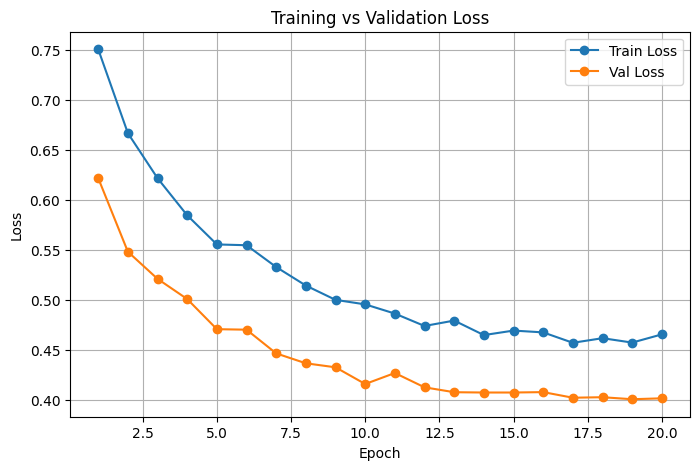

In [ ]:
# ----------  Plot Training Curves ----------
import matplotlib.pyplot as plt

def plot_training_curves(log_path):
    with open(log_path, "r") as f:
        lines = f.readlines()

    epochs, train_losses, val_losses = [], [], []
    for line in lines:
        if "Epoch" in line and "Train loss" in line:
            parts = line.strip().split()
            ep = int(parts[1].split("/")[0])
            # parts looks like: ['Epoch','1/20','-','Train','loss:','0.6735','-','Val','loss:','0.5742']
            t_loss = float(parts[5])
            v_loss = float(parts[9])
            epochs.append(ep)
            train_losses.append(t_loss)
            val_losses.append(v_loss)

    plt.figure(figsize=(8,5))
    plt.plot(epochs, train_losses, label="Train Loss", marker="o")
    plt.plot(epochs, val_losses, label="Val Loss", marker="o")
    plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage after training
log_path = Path(CONFIG['save_dir']) / f"{EXP['name']}_training.log"
plot_training_curves(log_path)


In [ ]:
# ---------- Evaluation ----------
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Load best model
best_w_path = Path(CONFIG['save_dir']) / f"{EXP['name']}_best.pth"
print("Evaluating:", best_w_path)
model_smp.load_state_dict(torch.load(best_w_path, map_location=DEVICE))
model_smp.eval()

def evaluate_model(model, dataloader, threshold=0.5):
    all_preds, all_targets = [], []
    running_loss, nb = 0, 0
    with torch.no_grad():
        for imgs, masks in dataloader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

            # Ensure masks shape [B,1,H,W]
            if masks.ndim == 4 and masks.shape[1] != 1:
                masks = masks.permute(0, 3, 1, 2)
            elif masks.ndim == 3:
                masks = masks.unsqueeze(1)

            logits = model(imgs)
            probs = torch.sigmoid(logits)
            preds = (probs > threshold).float()

            all_preds.append(preds.cpu().numpy())
            all_targets.append(masks.cpu().numpy())

    y_true = np.concatenate(all_targets).reshape(-1)
    y_pred = np.concatenate(all_preds).reshape(-1)

    # Metrics
    intersection = np.logical_and(y_true == 1, y_pred == 1).sum()
    union = np.logical_or(y_true == 1, y_pred == 1).sum()
    iou = intersection / (union + 1e-8)

    dice = (2 * intersection) / (y_true.sum() + y_pred.sum() + 1e-8)

    print(f"Test IoU: {iou:.4f} | Test Dice: {dice:.4f}\n")

    print("Classification report (threshold=0.5):")
    print(classification_report(
        y_true, y_pred, target_names=["Background", "Water"]
    ))

    return iou, dice, y_true, y_pred

test_iou, test_dice, y_true, y_pred = evaluate_model(model_smp, test_dl_smp)


Evaluating: C:\Users\Eng.Razan\Documents\Cellula Projects\Cellula-intern\experiments_enhanced\smp_unet_res34_best.pth


C:\Users\Eng.Razan\AppData\Local\Temp\ipykernel_22368\1905708353.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_smp.load_state_dict(torch.load(best_w_path, map_lo

Test IoU: 0.7373 | Test Dice: 0.8488

Classification report (threshold=0.5):
              precision    recall  f1-score   support

  Background       0.92      0.93      0.92    493769
       Water       0.86      0.84      0.85    259895

    accuracy                           0.90    753664
   macro avg       0.89      0.88      0.89    753664
weighted avg       0.90      0.90      0.90    753664



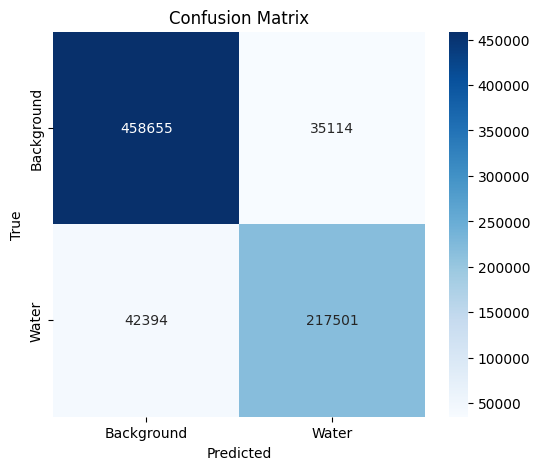

In [ ]:
# ---------- Confusion Matrix ----------
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Background","Water"], yticklabels=["Background","Water"])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix")
plt.show()


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


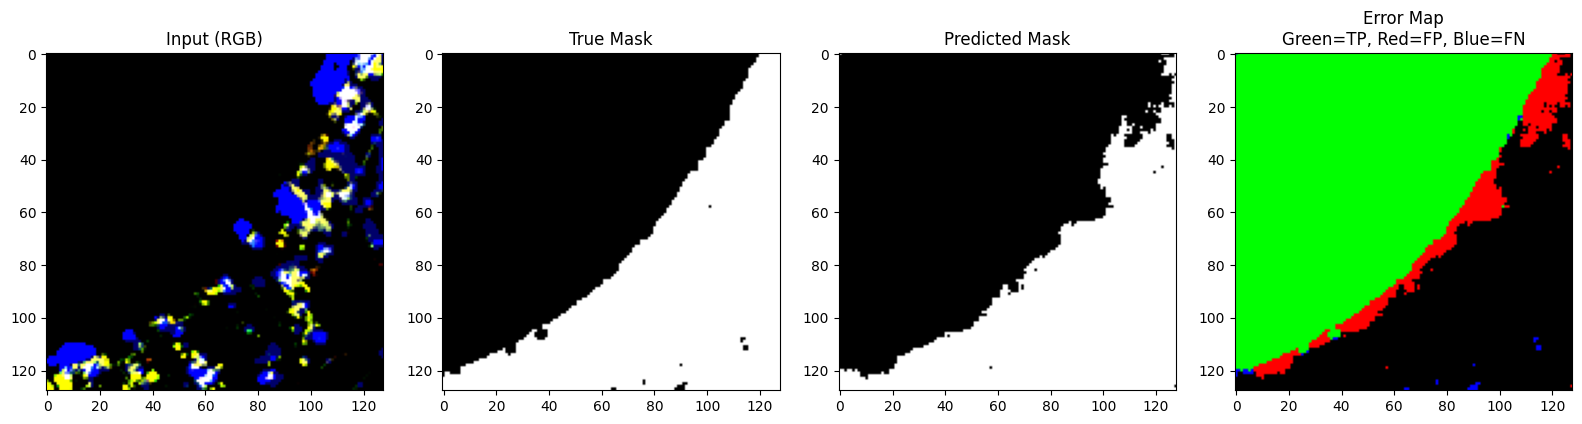

In [ ]:
# ----------  Visual check with error map ----------
import random
import numpy as np
import matplotlib.pyplot as plt

model_smp.eval()
imgs, masks = next(iter(test_dl_smp))
imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

with torch.no_grad():
    logits = model_smp(imgs)
    preds = torch.sigmoid(logits) > 0.5

# Pick random sample
idx = random.randint(0, imgs.size(0)-1)
img = imgs[idx].cpu().permute(1,2,0).numpy()
mask_true = masks[idx].cpu().squeeze().numpy().astype(np.uint8)
mask_pred = preds[idx].cpu().squeeze().numpy().astype(np.uint8)

# Error map: TP=green, FP=red, FN=blue
error_map = np.zeros((mask_true.shape[0], mask_true.shape[1], 3), dtype=np.uint8)
error_map[(mask_true==1) & (mask_pred==1)] = [0,255,0]   # TP green
error_map[(mask_true==0) & (mask_pred==1)] = [255,0,0]   # FP red
error_map[(mask_true==1) & (mask_pred==0)] = [0,0,255]   # FN blue

# Plot
plt.figure(figsize=(16,4))
plt.subplot(1,4,1); plt.imshow(img[..., :3]); plt.title("Input (RGB)")
plt.subplot(1,4,2); plt.imshow(mask_true, cmap="gray_r"); plt.title("True Mask")
plt.subplot(1,4,3); plt.imshow(mask_pred, cmap="gray_r"); plt.title("Predicted Mask")
plt.subplot(1,4,4); plt.imshow(error_map); plt.title("Error Map\nGreen=TP, Red=FP, Blue=FN")
plt.tight_layout()
plt.show()
